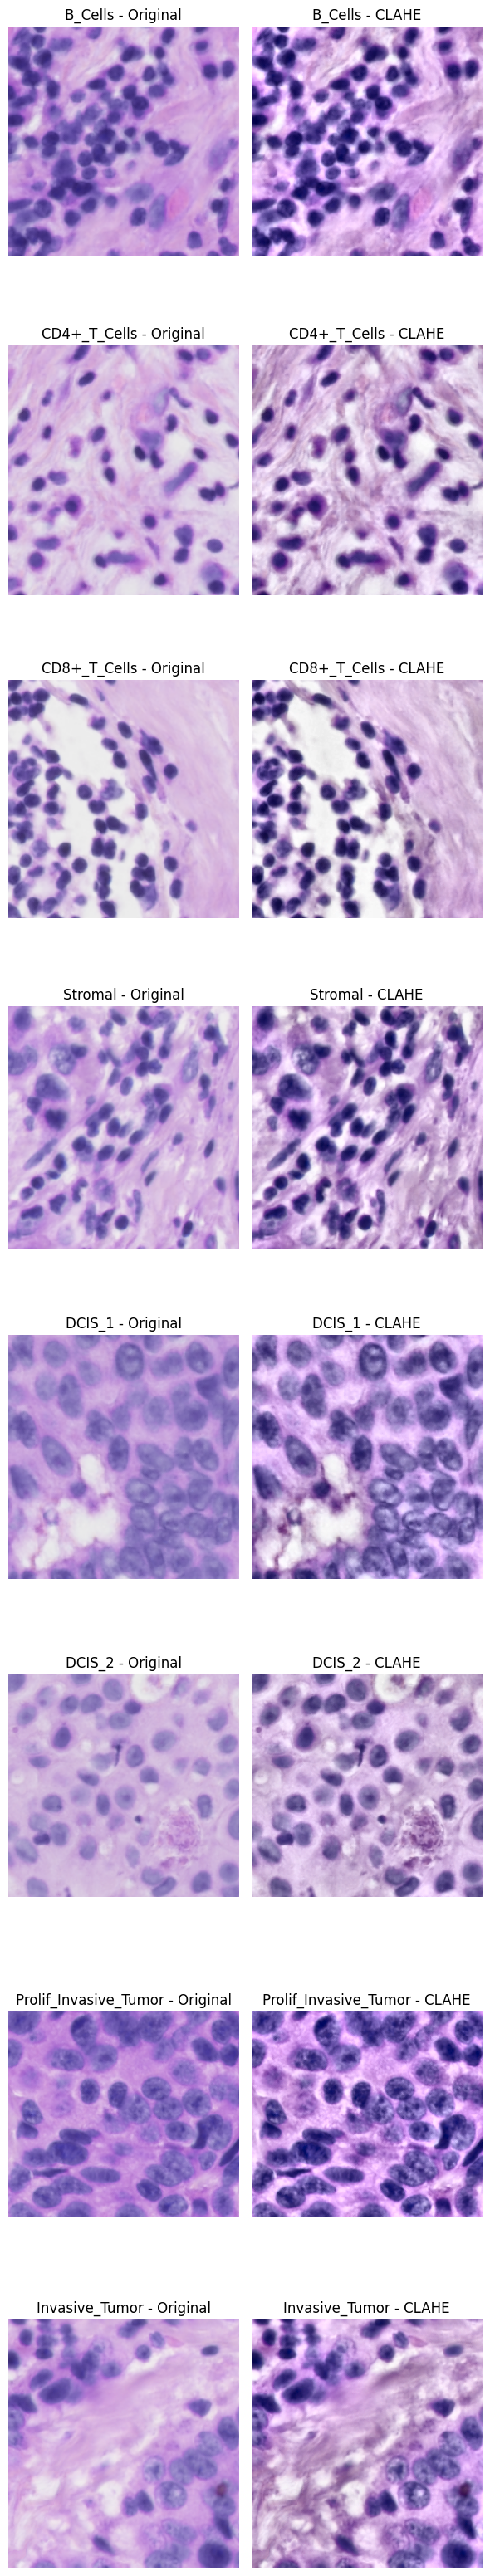

In [3]:
!pip install seaborn
!pip install scikit-learn
!pip install opencv-python
!pip install matplotlib
import os
import cv2
import shutil
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from collections import defaultdict
import random

# Set root directory
root_dir = "/Users/hannahsubbaraman/Desktop/100"
cell_types = ["B_Cells", "CD4+_T_Cells", "CD8+_T_Cells", "Stromal", 
              "DCIS_1", "DCIS_2", "Prolif_Invasive_Tumor", "Invasive_Tumor"]

# CLAHE function
def apply_clahe(img_rgb):
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    cl = clahe.apply(l)
    limg = cv2.merge((cl, a, b))
    return cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)

# Plot original vs CLAHE for one random image per cell type
fig, axes = plt.subplots(len(cell_types), 2, figsize=(6, 4 * len(cell_types)))
for i, cell_type in enumerate(cell_types):
    folder = os.path.join(root_dir, cell_type)
    files = [f for f in os.listdir(folder) if f.endswith(".png")]
    if not files:
        continue
    random_file = random.choice(files)
    img_path = os.path.join(folder, random_file)
    
    img_bgr = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_clahe = apply_clahe(img_rgb)

    axes[i, 0].imshow(img_rgb)
    axes[i, 0].set_title(f"{cell_type} - Original")
    axes[i, 1].imshow(img_clahe)
    axes[i, 1].set_title(f"{cell_type} - CLAHE")
    axes[i, 0].axis('off')
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

In [4]:


# Paths
original_dataset = "/Users/hannahsubbaraman/Desktop/100"
clahe_dataset = "/Users/hannahsubbaraman/Desktop/clahe_dataset"

# CLAHE parameters
clip_limit = 2.0
tile_grid_size = (8, 8)

def apply_clahe(img_rgb):
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
    cl = clahe.apply(l)
    limg = cv2.merge((cl, a, b))
    return cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)

def process_and_save_clahe(input_dir, output_dir):
    if os.path.exists(output_dir):
        shutil.rmtree(output_dir)
    os.makedirs(output_dir)

    for subdir, dirs, files in os.walk(input_dir):
        for file in files:
            if file.endswith(".png"):
                rel_path = os.path.relpath(subdir, input_dir)
                save_dir = os.path.join(output_dir, rel_path)
                os.makedirs(save_dir, exist_ok=True)

                img_path = os.path.join(subdir, file)
                img = cv2.imread(img_path)
                img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                processed = apply_clahe(img_rgb)
                processed_bgr = cv2.cvtColor(processed, cv2.COLOR_RGB2BGR)
                cv2.imwrite(os.path.join(save_dir, file), processed_bgr)

    print(f"CLAHE dataset saved to: {output_dir}")

# Run it
process_and_save_clahe(original_dataset, clahe_dataset)

KeyboardInterrupt: 

In [ ]:
seed = 3888
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

img_width, img_height = 100, 100
batch_size = 512
AUTOTUNE = tf.data.AUTOTUNE

tumour_folders = ["Invasive_Tumor", "DCIS_1", "DCIS_2", "Prolif_Invasive_Tumor"]
immune_folders = ["CD4+_T_Cells", "CD8+_T_Cells", "B_Cells", "Stromal"]
sub_label_list = tumour_folders + immune_folders
sub_label_to_index = {name: idx for idx, name in enumerate(sub_label_list)}

def get_file_label_pairs(folders, main_label, base_dir=""):
    pairs = []
    for folder in folders:
        full_path = os.path.join(base_dir, folder) if base_dir else folder
        files = tf.io.gfile.glob(os.path.join(full_path, "*.png"))
        for f in files:
            sub_label = os.path.basename(folder)
            pairs.append((f, main_label, sub_label))
    return pairs

# Load original (non-CLAHE)
tumour_files = get_file_label_pairs(tumour_folders, main_label=1, base_dir=original_dataset)
immune_files = get_file_label_pairs(immune_folders, main_label=0, base_dir=original_dataset)
all_file_label_pairs = tumour_files + immune_files
balanced_pairs = create_balanced_equal_dataset(all_file_label_pairs, target_size=15000)
train_ds_over, test_ds_over = prepare_dataset(balanced_pairs)

# Load CLAHE
clahe_tumour_files = get_file_label_pairs(tumour_folders, main_label=1, base_dir=clahe_dataset)
clahe_immune_files = get_file_label_pairs(immune_folders, main_label=0, base_dir=clahe_dataset)
clahe_all_pairs = clahe_tumour_files + clahe_immune_files
balanced_pairs_clahe = create_balanced_equal_dataset(clahe_all_pairs, target_size=15000)
train_ds_clahe, test_ds_clahe = prepare_dataset(balanced_pairs_clahe)

def create_balanced_equal_dataset(file_label_pairs, target_size=15000):
    label_to_files = defaultdict(list)
    for f, main_label, sub_label in file_label_pairs:
        label_to_files[sub_label].append((f, main_label, sub_label))

    balanced = []
    for sub_label, files in label_to_files.items():
        originals = files.copy()
        current_size = len(originals)

        if current_size < target_size:
            extra_needed = target_size - current_size
            oversampled_files = random.choices(originals, k=extra_needed)
            balanced.extend((f, m, s, False) for f, m, s in originals)
            balanced.extend((f, m, s, True) for f, m, s in oversampled_files)
        elif current_size > target_size:
            undersampled_files = random.sample(originals, k=target_size)
            balanced.extend((f, m, s, False) for f, m, s in undersampled_files)
        else:
            balanced.extend((f, m, s, False) for f, m, s in originals)

    random.shuffle(balanced)
    return balanced

target_size = 15000
balanced_pairs = create_balanced_equal_dataset(all_file_label_pairs, target_size = target_size)
print(f"Total images each class balances to: {target_size}")
print(f"Total images after balancing: {len(balanced_pairs)}")

def augment_image(img):
    angles = [0, 90, 180, 270]
    angle = random.choice(angles)
    
    if angle == 90:
        img = tf.image.rot90(img, k=1)
    elif angle == 180:
        img = tf.image.rot90(img, k=2)
    elif angle == 270:
        img = tf.image.rot90(img, k=3)

    flip_type = random.choice(['none', 'horizontal', 'vertical', 'both'])
    if flip_type == 'horizontal':
        img = tf.image.flip_left_right(img)
    elif flip_type == 'vertical':
        img = tf.image.flip_up_down(img)
    elif flip_type == 'both':
        img = tf.image.flip_left_right(img)
        img = tf.image.flip_up_down(img)

    return img

def decode_img(img_path, augment=False):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.image.resize(img, [img_width, img_height])
    img = img / 255.0
    if augment:
        img = augment_image(img)
    return img

def prepare_dataset(pairs):
    file_paths, main_labels, sub_labels, augment_flags = [], [], [], []

    for f, m, s, a in pairs:
        file_paths.append(f)
        main_labels.append(m)
        sub_labels.append(sub_label_to_index[s])
        augment_flags.append(a)

    file_paths = np.array(file_paths)
    main_labels = np.array(main_labels)
    sub_labels = np.array(sub_labels)
    augment_flags = np.array(augment_flags)

    train_files, test_files, train_main, test_main, train_sub, test_sub, train_aug, test_aug = train_test_split(
        file_paths, main_labels, sub_labels, augment_flags, test_size=0.3, stratify=sub_labels, random_state=seed
    )

    def process_path(file_path, main_label, sub_label, augment):
        img = decode_img(file_path, augment)
        return img, {"binary_output": main_label, "multiclass_output": sub_label}

    train_ds = tf.data.Dataset.from_tensor_slices((train_files, train_main, train_sub, train_aug))
    train_ds = train_ds.map(process_path, num_parallel_calls=AUTOTUNE).shuffle(1000).batch(batch_size).prefetch(AUTOTUNE)

    test_ds = tf.data.Dataset.from_tensor_slices((test_files, test_main, test_sub, test_aug))
    test_ds = test_ds.map(process_path, num_parallel_calls=AUTOTUNE).batch(batch_size).prefetch(AUTOTUNE)

    return train_ds, test_ds

def build_multitask_model():
    inputs = tf.keras.Input(shape=(img_width, img_height, 3))
    x = tf.keras.layers.Conv2D(32, (3,3), activation='relu')(inputs)
    x = tf.keras.layers.MaxPooling2D((2,2))(x)
    x = tf.keras.layers.Conv2D(64, (3,3), activation='relu')(x)
    x = tf.keras.layers.MaxPooling2D((2,2))(x)
    x = tf.keras.layers.Flatten()(x)
    x = tf.keras.layers.Dense(128, activation='relu')(x)

    binary_output = tf.keras.layers.Dense(1, activation='sigmoid', name="binary_output")(x)
    multiclass_logits = tf.keras.layers.Dense(8, name="raw_multiclass_logits")(x)
    scaled_logits = tf.keras.layers.Multiply()([multiclass_logits, binary_output])
    multiclass_output = tf.keras.layers.Activation('softmax', name="multiclass_output")(scaled_logits)

    model = tf.keras.Model(inputs=inputs, outputs=[binary_output, multiclass_output])

    model.compile(
        optimizer='adam',
        loss={
            "binary_output": "binary_crossentropy",
            "multiclass_output": "sparse_categorical_crossentropy"
        },
        metrics={
            "binary_output": "accuracy",
            "multiclass_output": "accuracy"
        }
    )

    return model

def plot_training_history(history):
    acc_bin = history.history['binary_output_accuracy']
    val_acc_bin = history.history['val_binary_output_accuracy']
    acc_multi = history.history['multiclass_output_accuracy']
    val_acc_multi = history.history['val_multiclass_output_accuracy']

    loss_bin = history.history['binary_output_loss']
    val_loss_bin = history.history['val_binary_output_loss']
    loss_multi = history.history['multiclass_output_loss']
    val_loss_multi = history.history['val_multiclass_output_loss']

    epochs_range = range(1, len(acc_bin) + 1)

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc_bin, marker='o', label='Train Binary Acc')
    plt.plot(epochs_range, val_acc_bin, marker='o', label='Val Binary Acc')
    plt.plot(epochs_range, acc_multi, marker='o', label='Train Multiclass Acc')
    plt.plot(epochs_range, val_acc_multi, marker='o', label='Val Multiclass Acc')
    plt.title('Accuracy Over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss_bin, marker='o', label='Train Binary Loss')
    plt.plot(epochs_range, val_loss_bin, marker='o', label='Val Binary Loss')
    plt.plot(epochs_range, loss_multi, marker='o', label='Train Multiclass Loss')
    plt.plot(epochs_range, val_loss_multi, marker='o', label='Val Multiclass Loss')
    plt.title('Loss Over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

def train_and_evaluate(train_ds, test_ds, title="Model"):
    model = build_multitask_model()
    model.summary()

    history = model.fit(train_ds, epochs=10, validation_data=test_ds)

    results = model.evaluate(test_ds)
    print(f"\nTest results - {title}:")
    print(f"Binary Accuracy: {results[3]:.4f}")
    print(f"Multiclass Accuracy: {results[4]:.4f}")

    y_true, y_pred = [], []

    for images, labels in test_ds:
        preds = model.predict(images, verbose=0)
        bin_preds = preds[0].flatten()
        multi_preds = preds[1]

        true_bin = labels['binary_output'].numpy().flatten()
        true_multi = labels['multiclass_output'].numpy().flatten()

        tumour_indices = np.where(true_bin == 1)[0]
        if len(tumour_indices) > 0:
            y_true.extend(true_multi[tumour_indices])
            y_pred.extend(np.argmax(multi_preds[tumour_indices], axis=1))

    if y_true and y_pred:
        y_true_tumour = np.array(y_true)
        y_pred_tumour = np.array(y_pred)

    plot_training_history(history)

    return model, y_true_tumour, y_pred_tumour

def plot_confusion_and_report(y_true, y_pred, labels, label_names, title="Confusion Matrix"):
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, labels=labels, target_names=label_names))

    cm = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

train_ds_over, test_ds_over = prepare_dataset(balanced_pairs)

# Train model on original data
print("\n--- Training on Original Images ---")
model_over, y_true_orig, y_pred_orig = train_and_evaluate(train_ds_over, test_ds_over, title="Original")

# Train model on CLAHE data
print("\n--- Training on CLAHE Images ---")
model_clahe, y_true_clahe, y_pred_clahe = train_and_evaluate(train_ds_clahe, test_ds_clahe, title="CLAHE")

tumour_labels = [0, 1, 2, 3]  # Indices corresponding to the tumour subtypes
tumour_folders = ["Invasive_Tumor", "DCIS_1", "DCIS_2", "Prolif_Invasive_Tumor"]

# Plot confusion matrix for original images
plot_confusion_and_report(
    y_true_orig, 
    y_pred_orig, 
    labels=tumour_labels, 
    label_names=tumour_folders, 
    title="Confusion Matrix – Original Images"
)

# Plot confusion matrix for CLAHE images
plot_confusion_and_report(
    y_true_clahe, 
    y_pred_clahe, 
    labels=tumour_labels, 
    label_names=tumour_folders, 
    title="Confusion Matrix – CLAHE Images"
)